# 02 · The inverted file: skip comparisons by clustering

**The question.** Exact search scores every vector. Which ones could we skip, and what does
skipping cost?

**The claim.** Cluster the database once with k-means. At query time, rank the cluster centres
by distance and scan only the vectors in the few nearest clusters. One knob — `nprobe`, how many
clusters to scan — slides from fast and approximate (`nprobe = 1`) to slow and exact
(`nprobe = nlist`). Recall becomes a dial you set, and you can read its price off a curve.

**By the end** you will have built an inverted-file index (IVF) from scratch, watched it miss
neighbours that sit across a cluster border, and measured the recall-for-speed trade on real
and synthetic vectors — in work done and in wall-clock time.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import visualisation as vis
from src.artifacts import save_figure, save_json
from src.config import get_settings
from src.datasets.vectors import load_dataset
from src.evaluation.speed import machine_info, pinned_threads

S = get_settings()
K, SEED, THREADS = S.eval.k, S.seed, S.bench.threads
NB_START = time.perf_counter()
MACHINE = machine_info(THREADS)
pd.set_option("display.width", 140, "display.max_colwidth", 90)


def show(fig, slug: str) -> None:
    """Save the figure as outputs/figures/<slug>.png, then display it once."""
    save_figure(fig, slug)
    plt.close(fig)
    display(fig)


print(MACHINE)

{'cpu': 'Intel(R) Xeon(R) Platinum 8370C CPU @ 2.80GHz', 'logical_cpus': 2, 'threads': 1, 'python': '3.14.2', 'numpy': '2.5.4', 'faiss': '1.15.1', 'hnswlib': '0.8.0'}


## How it works, in two dimensions

`src/indexes/ivf.py` has three steps:

1. **Train.** k-means learns `nlist` centroids — the *coarse quantizer*. Each centroid owns a
   Voronoi cell: the region of space closer to it than to any other centroid.
2. **Add.** Each vector goes into the *inverted list* of its nearest centroid.
3. **Search.** Compute the query's distance to the `nlist` centroids, scan the `nprobe`
   nearest lists exactly, keep the k best.

The picture below uses 2,000 points in 2-D and 12 cells, with a query chosen to sit near a
border (the held-out point whose recall at `nprobe = 1` is closest to one half).

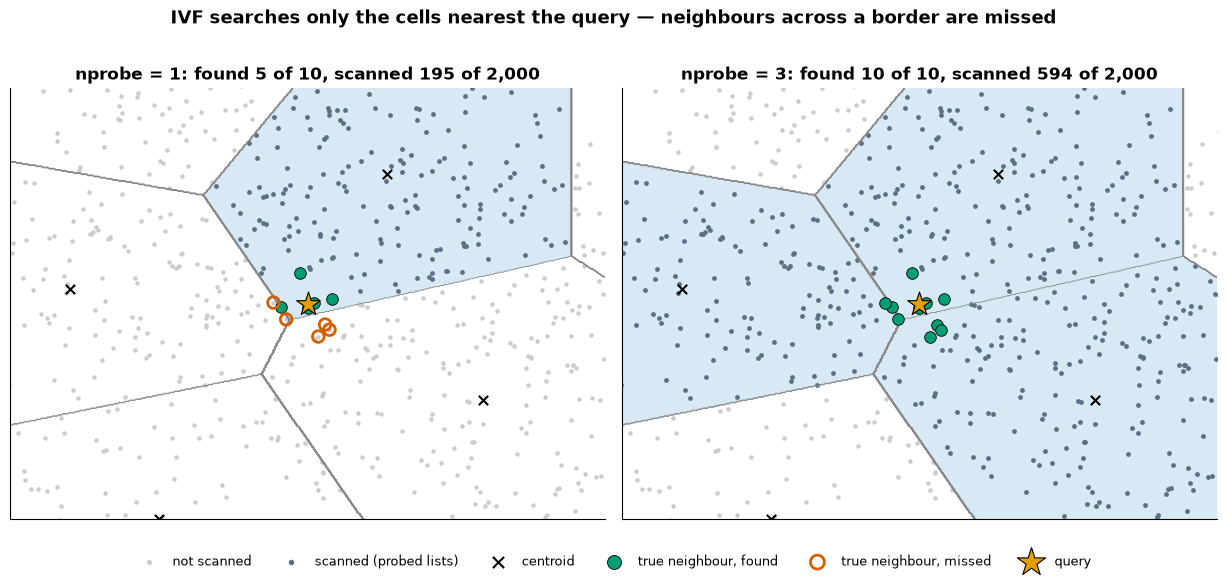

[{'nprobe': 1, 'probed_lists': [0], 'true_found': 5, 'vectors_scanned': 195},
 {'nprobe': 3,
  'probed_lists': [0, 1, 8],
  'true_found': 10,
  'vectors_scanned': 594}]

In [2]:
from src.datasets.vectors import exact_ground_truth, make_synthetic
from src.evaluation.recall import per_query_recall, recall_at_k
from src.indexes.ivf import IVFIndex, assign_to_nearest

toy = make_synthetic(2200, 2, n_clusters=8, intrinsic_dim=2, cluster_std=0.6, noise=0.0, seed=SEED)
toy_base, toy_queries = toy[200:], toy[:200]
toy_ivf = IVFIndex(nlist=S.ivf.toy_nlist, seed=SEED)
toy_ivf.train(toy_base)
toy_ivf.add(toy_base)
toy_gt, _ = exact_ground_truth(toy_base, toy_queries, K)

toy_ivf.nprobe = 1
_, ids1 = toy_ivf.search(toy_queries, K)
r1 = per_query_recall(ids1, toy_gt, K)
qi = int(np.argmin(np.abs(r1 - 0.5)))  # the query that straddles a border most evenly
query = toy_queries[qi]

point_lists = np.empty(toy_base.shape[0], dtype=np.int64)
for j, ids in enumerate(toy_ivf.list_ids):
    point_lists[ids] = j
span = float(np.sort(np.linalg.norm(toy_ivf.centroids - query, axis=1))[2]) * 1.3
xs = np.linspace(query[0] - span, query[0] + span, 400)
ys = np.linspace(query[1] - span, query[1] + span, 400)
xx, yy = np.meshgrid(xs, ys)
cell = assign_to_nearest(np.c_[xx.ravel(), yy.ravel()].astype(np.float32), toy_ivf.centroids).reshape(xx.shape)

panels, toy_record = [], []
for nprobe in (1, 3):
    toy_ivf.nprobe = nprobe
    tr = toy_ivf.trace(query, K)
    found = sorted(set(tr.ids) & set(toy_gt[qi].tolist()))
    panels.append({"nprobe": nprobe, "probed": tr.probed_lists, "found": found, "scanned": tr.n_candidates})
    toy_record.append({"nprobe": nprobe, "probed_lists": tr.probed_lists, "true_found": len(found),
                       "vectors_scanned": tr.n_candidates})
fig = vis.plot_ivf_toy(toy_base, toy_ivf.centroids, (xx, yy, cell), point_lists, query, toy_gt[qi], panels)
show(fig, "02_ivf_toy_cells")
save_json("02_ivf_toy_cells", {"n": toy_base.shape[0], "nlist": S.ivf.toy_nlist, "k": K,
                               "query_index": qi, "query": query, "panels": toy_record})
toy_record

The query's true neighbours (ringed) straddle a border. With `nprobe = 1` the index scans one
cell and misses everything on the other side; probing the 3 nearest cells finds them — at the
price of scanning more vectors. That is the whole idea, and the whole cost.

## The dial, on real and synthetic vectors

Now the real thing: `nlist = 256` lists, `nprobe` swept from 1 to 256, on three datasets with
1,000 held-out queries each:

- **news** — 50,000 MiniLM sentence embeddings (384-d), the structure semantic search sees;
- **clustered** — 200,000 synthetic vectors from 200 Gaussian clusters on a 16-d subspace of 128-d;
- **isotropic** — 50,000 vectors from one fat 128-d Gaussian: no clusters, nothing to exploit.

Speed is reported first as **work** — vectors scored per query, so `N / work` is the speedup
over exact search in comparisons. It does not depend on hardware or on Python being slow.

In [3]:
from src.evaluation.speed import timed_build
from src.evaluation.triangle import expand_params, sweep, to_frame

datasets = {name: load_dataset(name) for name in ("news", "clustered", "isotropic")}
ivf_cfg = S.ivf
rows = []
with pinned_threads(THREADS):
    for name, ds in datasets.items():
        index = IVFIndex(nlist=ivf_cfg.nlist, train_points_per_centroid=ivf_cfg.train_points_per_centroid,
                         kmeans_max_iter=ivf_cfg.kmeans_max_iter, seed=SEED)
        build_s = timed_build(index, ds.base)
        rows += sweep(index, "nprobe", ivf_cfg.nprobe_sweep, ds.queries, ds.gt_ids, K,
                      engine="scratch", dataset=name, build_params={"nlist": ivf_cfg.nlist},
                      build_s=build_s, seed=SEED, threads=THREADS)
        if name == "news":
            news_ivf = index
scratch = expand_params(to_frame(rows))
display(scratch.pivot(index="nprobe", columns="dataset", values="recall").round(3))

dataset,clustered,isotropic,news
nprobe,,,
1,0.926,0.038,0.423
2,0.992,0.064,0.575
4,1.000,0.109,0.711
8,1.000,0.185,0.811
16,1.000,0.300,0.889
32,1.000,0.458,0.944
64,1.000,0.674,0.977
128,1.000,0.912,0.994
256,1.000,1.000,1.000


Next, the same index in faiss (`IndexIVFFlat`, compiled C++), timed one query at a time on one
thread, against faiss's exact `IndexFlatL2` on the same data. This is the honest wall-clock
check: our Python loop over lists would measure the interpreter, not the algorithm.

In [4]:
from src.evaluation.speed import median_latency_ms
from src.reference.compare import FaissFlat, FaissIVF

bench = S.bench
compiled_rows = []
with pinned_threads(THREADS):
    for name in ("news", "clustered"):
        ds = datasets[name]
        flat = FaissFlat()
        flat.add(ds.base)
        exact_ms = median_latency_ms(flat, ds.queries, K, warmup=bench.warmup, max_queries=bench.max_queries)
        ref = FaissIVF(nlist=ivf_cfg.nlist, kmeans_max_iter=ivf_cfg.kmeans_max_iter, seed=SEED)
        build_s = timed_build(ref, ds.base)
        compiled_rows += sweep(ref, "nprobe", ivf_cfg.nprobe_sweep, ds.queries, ds.gt_ids, K,
                               engine="faiss", dataset=name, build_params={"nlist": ivf_cfg.nlist},
                               build_s=build_s, seed=SEED, threads=THREADS, timed=True,
                               warmup=bench.warmup, max_queries=bench.max_queries,
                               exact_latency_ms=exact_ms)
        del flat, ref
compiled = expand_params(to_frame(compiled_rows))
display(compiled[["dataset", "nprobe", "recall", "latency_ms", "speedup_vs_exact"]].round(3))

,dataset,nprobe,recall,latency_ms,speedup_vs_exact
0,news,1,0.455,0.063,97.201
1,news,2,0.601,0.096,64.077
2,news,4,0.727,0.132,46.262
3,news,8,0.828,0.240,25.506
4,news,16,0.896,0.395,15.527
5,news,32,0.947,0.722,8.491
6,news,64,0.978,1.376,4.455
7,news,128,0.995,2.840,2.158
8,news,256,1.000,6.282,0.976
9,clustered,1,0.926,0.057,155.300


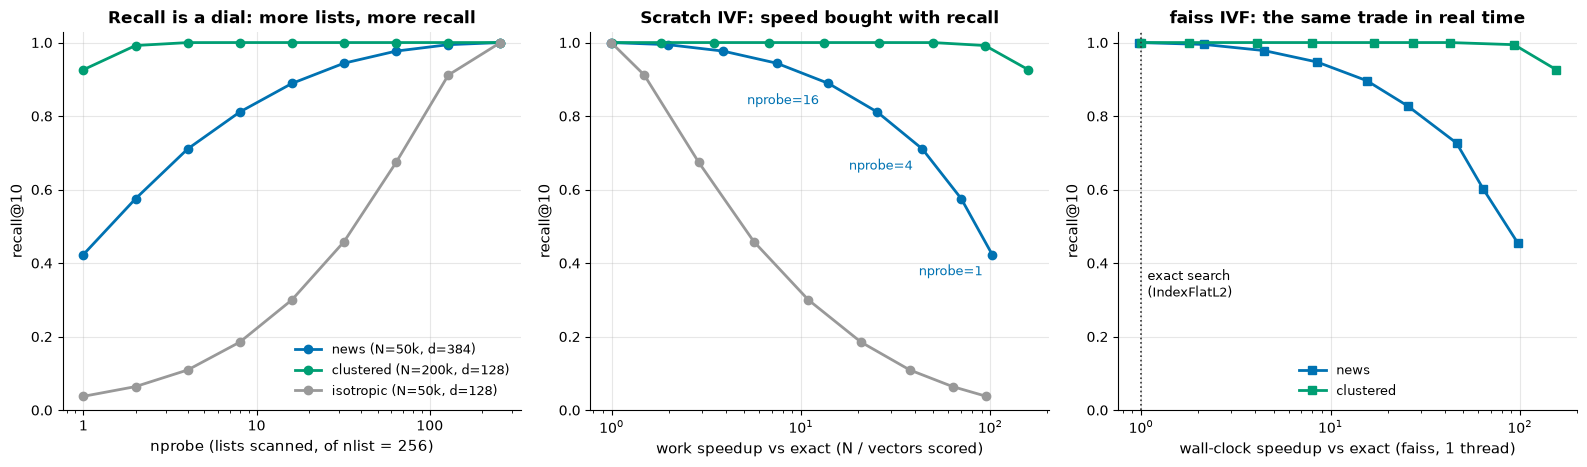

PosixPath('/workspaces/vector_search_101/outputs/results/02_ivf_nprobe_sweep.json')

In [5]:
fig = vis.plot_ivf_sweep(scratch, compiled, K)
show(fig, "02_ivf_nprobe_sweep")
cols = ["dataset", "n", "d", "nprobe", "recall", "work", "work_speedup", "latency_ms", "speedup_vs_exact", "build_s"]
save_json("02_ivf_nprobe_sweep", {"k": K, "nlist": ivf_cfg.nlist, "machine": MACHINE,
                                  "scratch": scratch[cols], "faiss": compiled[cols]})

Three things to read off these curves:

- **Recall is a dial.** On every dataset recall climbs with `nprobe` and reaches exactly 1.0 at
  `nprobe = nlist`, where every list is scanned and IVF *is* exact search (plus 256 wasted
  centroid distances). In between, you choose your point.
- **Structure is what IVF exploits.** On the clustered set a handful of lists already holds the
  neighbours. On the isotropic control the neighbours are scattered across many cells, so the
  same recall costs far more lists. Real embeddings sit in between.
- **The trade is real in wall-clock time too.** faiss turns the same work savings into actual
  speedups over its own exact search; at full probe the speedup is back to about 1x, because IVF
  then does exact search's work plus the centroid ranking.

## Where the misses come from

Why does a query miss neighbours at `nprobe = 1`? Measure how close each query sits to a cell
border: the ratio of its distance to the second-nearest centroid over the nearest. A ratio near
1 means the query is almost equidistant from two cells — its neighbours are likely split
between them.

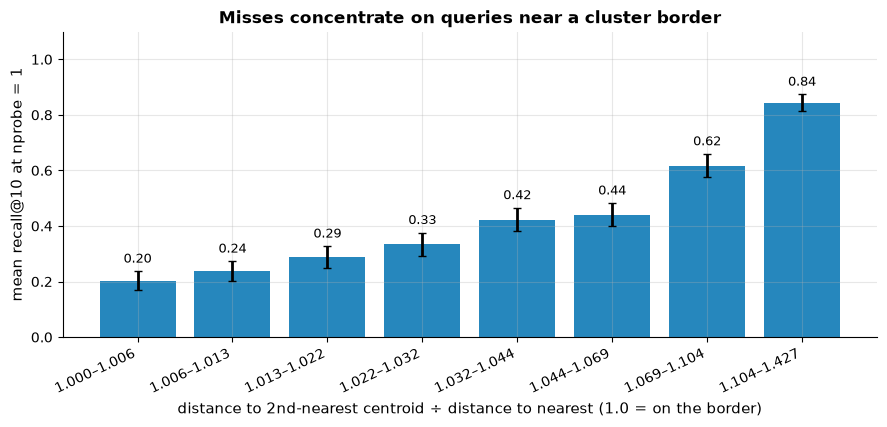

correlation between border margin and recall: 0.66


In [6]:
from src.metrics.distance import sq_l2

news = datasets["news"]
news_ivf.nprobe = 1
_, ids = news_ivf.search(news.queries, K)
recall_q = per_query_recall(ids, news.gt_ids, K)
cd = np.sqrt(np.sort(sq_l2(news.queries, news_ivf.centroids), axis=1)[:, :2])
margin = cd[:, 1] / cd[:, 0]

fig = vis.plot_ivf_misses(margin, recall_q)
show(fig, "02_ivf_misses_near_borders")
corr = float(np.corrcoef(margin, recall_q)[0, 1])
quartiles = np.quantile(margin, [0.25, 0.75])
save_json("02_ivf_misses_near_borders", {
    "dataset": "news", "nprobe": 1, "k": K, "corr_margin_recall": corr,
    "mean_recall_bottom_quartile_margin": float(recall_q[margin <= quartiles[0]].mean()),
    "mean_recall_top_quartile_margin": float(recall_q[margin >= quartiles[1]].mean()),
    "mean_recall_all": float(recall_q.mean()),
})
print(f"correlation between border margin and recall: {corr:.2f}")

In [7]:
def at(df, name, nprobe, col):
    return float(df[(df["dataset"] == name) & (df["nprobe"] == nprobe)][col].iloc[0])

target = 0.9
news_s = scratch[scratch["dataset"] == "news"].sort_values("nprobe")
first = news_s[news_s["recall"] >= target].iloc[0]
summary = {
    "news_recall_nprobe1": at(scratch, "news", 1, "recall"),
    "news_recall_nprobe16": at(scratch, "news", 16, "recall"),
    "news_recall_full_probe": at(scratch, "news", ivf_cfg.nlist, "recall"),
    "news_first_nprobe_reaching_0.9": int(first["nprobe"]),
    "news_work_speedup_at_that_nprobe": float(first["work_speedup"]),
    "news_faiss_speedup_at_that_nprobe": at(compiled, "news", int(first["nprobe"]), "speedup_vs_exact"),
    "clustered_recall_nprobe4": at(scratch, "clustered", 4, "recall"),
    "isotropic_recall_nprobe4": at(scratch, "isotropic", 4, "recall"),
    "runtime_s": time.perf_counter() - NB_START,
}
save_json("02_summary", summary)
display(Markdown(f'''
### What this bought you, and what it cost

- **Bought:** on the news embeddings, `nprobe = {summary["news_first_nprobe_reaching_0.9"]}` of
  {ivf_cfg.nlist} lists reaches recall@10 of {target} while scoring
  {summary["news_work_speedup_at_that_nprobe"]:.0f}x fewer vectors than exact search (faiss turns
  that into a {summary["news_faiss_speedup_at_that_nprobe"]:.0f}x wall-clock speedup).
- **Cost:** recall. At `nprobe = 1` the index returns only {summary["news_recall_nprobe1"]:.0%} of
  the true neighbours; the misses sit across cluster borders. Recall reaches
  {summary["news_recall_full_probe"]:.0%} only when every list is scanned — when IVF has become
  exact search.
- **Structure matters:** at `nprobe = 4`, recall is {summary["clustered_recall_nprobe4"]:.2f} on
  clustered data and {summary["isotropic_recall_nprobe4"]:.2f} on the structureless control.
'''))
print(f"notebook runtime: {summary['runtime_s']:.0f} s")


### What this bought you, and what it cost

- **Bought:** on the news embeddings, `nprobe = 32` of
  256 lists reaches recall@10 of 0.9 while scoring
  7x fewer vectors than exact search (faiss turns
  that into a 8x wall-clock speedup).
- **Cost:** recall. At `nprobe = 1` the index returns only 42% of
  the true neighbours; the misses sit across cluster borders. Recall reaches
  100% only when every list is scanned — when IVF has become
  exact search.
- **Structure matters:** at `nprobe = 4`, recall is 1.00 on
  clustered data and 0.11 on the structureless control.


notebook runtime: 127 s
